TASK1: Data Collection & Web Scraping

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time

from bs4 import BeautifulSoup
from urllib.parse import urljoin

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
BASE_URL = "https://books.toscrape.com/"

HEADERS = {
    "User-Agent": "BookScope-DataAnalytics-Internship/1.0"
}

DATA_FOLDER = "data"
VISUALIZATION_FOLDER = "visualizations"

os.makedirs(DATA_FOLDER, exist_ok=True)
os.makedirs(VISUALIZATION_FOLDER, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [3]:
def fetch_page(url):

    try:
        response = requests.get(
            url,
            headers=HEADERS,
            timeout=20
        )

        response.raise_for_status()
        response.encoding = "utf-8"

        return response.text

    except requests.exceptions.RequestException as error:

        print("Error:", error)
        return None


html = fetch_page(BASE_URL)

if html:
    print("Website fetched successfully!")
    print("HTML characters:", len(html))
else:
    print("Unable to fetch website.")

Website fetched successfully!
HTML characters: 51274


In [4]:
soup = BeautifulSoup(html, "html.parser")

print(soup.title.text)

book_cards = soup.select("article.product_pod")

print("Books on first page:", len(book_cards))


    All products | Books to Scrape - Sandbox

Books on first page: 20


In [5]:
RATING_MAP = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}


def extract_books(html, page_url):

    soup = BeautifulSoup(html, "html.parser")

    book_cards = soup.select("article.product_pod")

    books = []

    for book in book_cards:

        # Title
        title_element = book.select_one("h3 a")
        title = title_element.get("title", "").strip()

        # Product URL
        relative_url = title_element.get("href", "")
        product_url = urljoin(page_url, relative_url)

        # Price
        price_text = book.select_one(
            ".price_color"
        ).get_text(strip=True)

        price = float(
            price_text.replace("£", "")
        )

        # Rating
        rating_element = book.select_one(
            ".star-rating"
        )

        rating_classes = rating_element.get("class", [])

        rating_word = next(
            (word for word in rating_classes
             if word in RATING_MAP),
            None
        )

        rating = RATING_MAP.get(rating_word)

        # Availability
        availability_text = book.select_one(
            ".availability"
        ).get_text(" ", strip=True)

        availability = (
            "In Stock"
            if "In stock" in availability_text
            else "Out of Stock"
        )

        # Store record
        books.append({
            "title": title,
            "price_gbp": price,
            "rating": rating,
            "availability": availability,
            "category": "All Books",
            "product_url": product_url
        })

    return books


first_page_books = extract_books(html, BASE_URL)

pd.DataFrame(first_page_books).head()

,title,price_gbp,rating,availability,category,product_url
0,A Light in the Attic,51.77,3,In Stock,All Books,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In Stock,All Books,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In Stock,All Books,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In Stock,All Books,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In Stock,All Books,https://books.toscrape.com/catalogue/sapiens-a...


In [6]:
all_books = []

current_url = BASE_URL
page_number = 1

while current_url:

    print(f"Scraping page {page_number}...")

    html = fetch_page(current_url)

    if html is None:
        print("Stopping due to request error.")
        break

    page_books = extract_books(
        html,
        current_url
    )

    if not page_books:
        print("No books found.")
        break

    all_books.extend(page_books)

    soup = BeautifulSoup(html, "html.parser")

    next_button = soup.select_one("li.next a")

    if next_button:

        next_page = next_button.get("href")

        current_url = urljoin(
            current_url,
            next_page
        )

        page_number += 1

        # Small delay between requests
        time.sleep(0.5)

    else:

        current_url = None


print("\nScraping completed!")
print("Total books collected:", len(all_books))

Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...
Scraping page 6...
Scraping page 7...
Scraping page 8...
Scraping page 9...
Scraping page 10...
Scraping page 11...
Scraping page 12...
Scraping page 13...
Scraping page 14...
Scraping page 15...
Scraping page 16...
Scraping page 17...
Scraping page 18...
Scraping page 19...
Scraping page 20...
Scraping page 21...
Scraping page 22...
Scraping page 23...
Scraping page 24...
Scraping page 25...
Scraping page 26...
Scraping page 27...
Scraping page 28...
Scraping page 29...
Scraping page 30...
Scraping page 31...
Scraping page 32...
Scraping page 33...
Scraping page 34...
Scraping page 35...
Scraping page 36...
Scraping page 37...
Scraping page 38...
Scraping page 39...
Scraping page 40...
Scraping page 41...
Scraping page 42...
Scraping page 43...
Scraping page 44...
Scraping page 45...
Scraping page 46...
Scraping page 47...
Scraping page 48...
Scraping page 49...
Scraping page 50...

Scraping

In [7]:
df_raw = pd.DataFrame(all_books)

print("Dataset shape:", df_raw.shape)

df_raw.head(10)

Dataset shape: (1000, 6)


,title,price_gbp,rating,availability,category,product_url
0,A Light in the Attic,51.77,3,In Stock,All Books,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In Stock,All Books,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In Stock,All Books,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In Stock,All Books,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In Stock,All Books,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,1,In Stock,All Books,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In Stock,All Books,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In Stock,All Books,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In Stock,All Books,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,1,In Stock,All Books,https://books.toscrape.com/catalogue/the-black...


In [8]:
raw_file = "data/books_raw.csv"

df_raw.to_csv(
    raw_file,
    index=False,
    encoding="utf-8"
)

print("Raw dataset saved successfully!")

Raw dataset saved successfully!


In [9]:
print("Dataset Information")
print("-------------------")

df_raw.info()

print("\nMissing Values")
print("--------------")

print(df_raw.isnull().sum())

print("\nDuplicate Records")
print("-----------------")

print(
    df_raw.duplicated(
        subset=["title", "product_url"]
    ).sum()
)

Dataset Information
-------------------
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         1000 non-null   str    
 1   price_gbp     1000 non-null   float64
 2   rating        1000 non-null   int64  
 3   availability  1000 non-null   str    
 4   category      1000 non-null   str    
 5   product_url   1000 non-null   str    
dtypes: float64(1), int64(1), str(4)
memory usage: 47.0 KB

Missing Values
--------------
title           0
price_gbp       0
rating          0
availability    0
category        0
product_url     0
dtype: int64

Duplicate Records
-----------------
0


In [10]:
df_cleaned = df_raw.copy()

# Remove duplicate books
df_cleaned.drop_duplicates(
    subset=["title", "product_url"],
    inplace=True
)

# Remove records with missing essential information
df_cleaned.dropna(
    subset=[
        "title",
        "price_gbp",
        "rating",
        "availability"
    ],
    inplace=True
)

# Convert data types
df_cleaned["title"] = (
    df_cleaned["title"]
    .astype(str)
    .str.strip()
)

df_cleaned["price_gbp"] = pd.to_numeric(
    df_cleaned["price_gbp"],
    errors="coerce"
)

df_cleaned["rating"] = pd.to_numeric(
    df_cleaned["rating"],
    errors="coerce"
)

# Remove invalid prices
df_cleaned = df_cleaned[
    df_cleaned["price_gbp"] >= 0
]

# Keep valid ratings
df_cleaned = df_cleaned[
    df_cleaned["rating"].between(1, 5)
]

# Remove any remaining missing values
df_cleaned.dropna(inplace=True)

# Reset index
df_cleaned.reset_index(
    drop=True,
    inplace=True
)

print("Data cleaning completed!")
print("Raw records:", len(df_raw))
print("Cleaned records:", len(df_cleaned))

df_cleaned.head()

Data cleaning completed!
Raw records: 1000
Cleaned records: 1000


C:\Users\balam\AppData\Local\Temp\ipykernel_28780\2188457287.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_cleaned.drop_duplicates(
C:\Users\balam\AppData\Local\Temp\ipykernel_28780\2188457287.py:10: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_cleaned.dropna(
C:\Users\balam\AppData\Local\Temp\ipykernel_28780\2188457287.py:48: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_cleaned.dropna(inplace=True)
C:\Users\balam\AppData\Local\Temp\ipykernel_28780

,title,price_gbp,rating,availability,category,product_url
0,A Light in the Attic,51.77,3,In Stock,All Books,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In Stock,All Books,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In Stock,All Books,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In Stock,All Books,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In Stock,All Books,https://books.toscrape.com/catalogue/sapiens-a...


In [11]:
print("DATA VALIDATION REPORT")
print("======================")

print(
    "Total records:",
    len(df_cleaned)
)

print(
    "Duplicate records:",
    df_cleaned.duplicated(
        subset=["title", "product_url"]
    ).sum()
)

print(
    "Missing values:",
    df_cleaned.isnull().sum().sum()
)

print(
    "Invalid prices:",
    (df_cleaned["price_gbp"] < 0).sum()
)

print(
    "Invalid ratings:",
    (~df_cleaned["rating"].between(1, 5)).sum()
)

DATA VALIDATION REPORT
Total records: 1000
Duplicate records: 0
Missing values: 0
Invalid prices: 0
Invalid ratings: 0


In [12]:
cleaned_file = "data/books_cleaned.csv"

df_cleaned.to_csv(
    cleaned_file,
    index=False,
    encoding="utf-8"
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [13]:
print("BOOK PRICE STATISTICS")
print("=====================")

print(df_cleaned["price_gbp"].describe())

print("\nAverage price:")
print(round(df_cleaned["price_gbp"].mean(), 2), "GBP")

print("\nMedian price:")
print(round(df_cleaned["price_gbp"].median(), 2), "GBP")

print("\nMost expensive book:")
print(
    df_cleaned.loc[
        df_cleaned["price_gbp"].idxmax(),
        "title"
    ]
)

print("\nLeast expensive book:")
print(
    df_cleaned.loc[
        df_cleaned["price_gbp"].idxmin(),
        "title"
    ]
)

BOOK PRICE STATISTICS
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price_gbp, dtype: float64

Average price:
35.07 GBP

Median price:
35.98 GBP

Most expensive book:
The Perfect Play (Play by Play #1)

Least expensive book:
An Abundance of Katherines


In [14]:
rating_counts = (
    df_cleaned["rating"]
    .value_counts()
    .sort_index()
)

print("Rating Distribution")
print("===================")

print(rating_counts)

print("\nMost common rating:")

print(
    df_cleaned["rating"].mode()[0]
)

Rating Distribution
rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Most common rating:
1


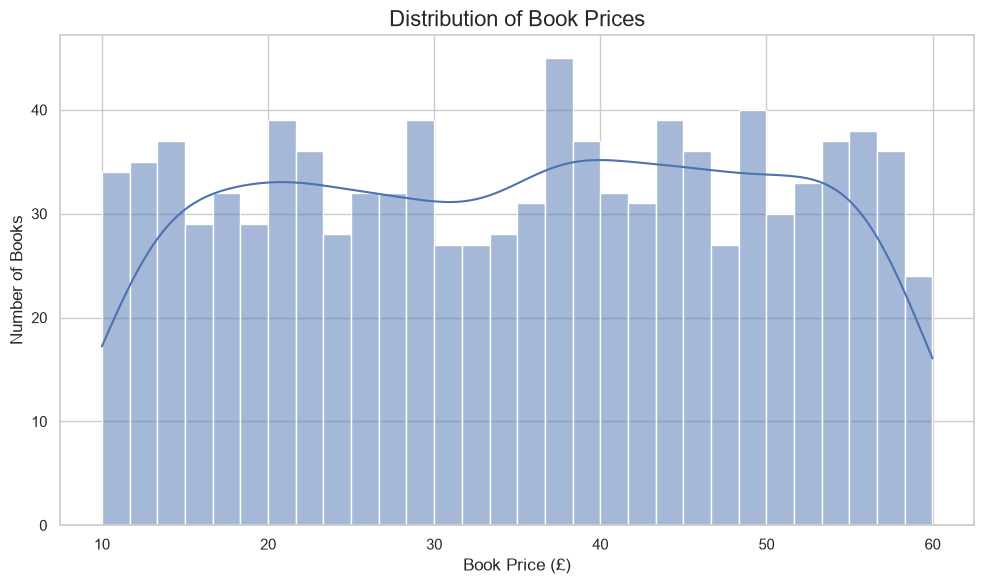

In [15]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_cleaned,
    x="price_gbp",
    bins=30,
    kde=True
)

plt.title(
    "Distribution of Book Prices",
    fontsize=16
)

plt.xlabel("Book Price (£)")
plt.ylabel("Number of Books")

plt.tight_layout()

plt.savefig(
    "visualizations/price_distribution.png",
    dpi=300
)

plt.show()

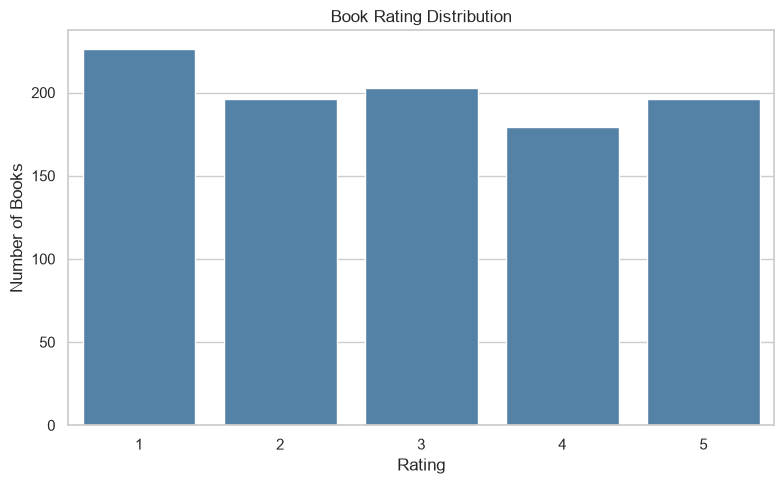

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_cleaned,
    x="rating",
    color="steelblue"
)

plt.title("Book Rating Distribution")

plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.tight_layout()

plt.savefig(
    "visualizations/rating_distribution.png",
    dpi=300
)

plt.show()

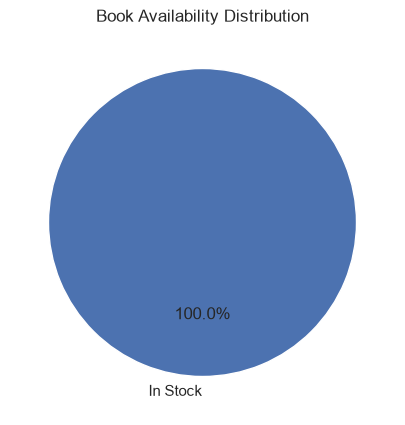

In [17]:
availability_counts = (
    df_cleaned["availability"]
    .value_counts()
)

plt.figure(figsize=(7, 5))

plt.pie(
    availability_counts,
    labels=availability_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Book Availability Distribution")

plt.savefig(
    "visualizations/availability_distribution.png",
    dpi=300
)

plt.show()

In [18]:
print("BOOKSCOPE — KEY FINDINGS")
print("========================")

print(
    "Total books analyzed:",
    len(df_cleaned)
)

print(
    "Average book price:",
    round(df_cleaned["price_gbp"].mean(), 2),
    "GBP"
)

print(
    "Median book price:",
    round(df_cleaned["price_gbp"].median(), 2),
    "GBP"
)

print(
    "Most common rating:",
    df_cleaned["rating"].mode()[0]
)

print(
    "Books in stock:",
    (df_cleaned["availability"] == "In Stock").sum()
)

print(
    "Books out of stock:",
    (df_cleaned["availability"] == "Out of Stock").sum()
)

print("\nAnalysis completed successfully!")

BOOKSCOPE — KEY FINDINGS
Total books analyzed: 1000
Average book price: 35.07 GBP
Median book price: 35.98 GBP
Most common rating: 1
Books in stock: 1000
Books out of stock: 0

Analysis completed successfully!
